In [1]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../Project_with_Jon/GPs.jl")
include("../Project_with_Jon/functions.jl")
include("../Project_with_Jon/myfuncs.jl")
include("../Project_with_Jon/integrators.jl")
include("../Project_with_Jon/util_shoji.jl")


simulate_pf_selforg (generic function with 1 method)

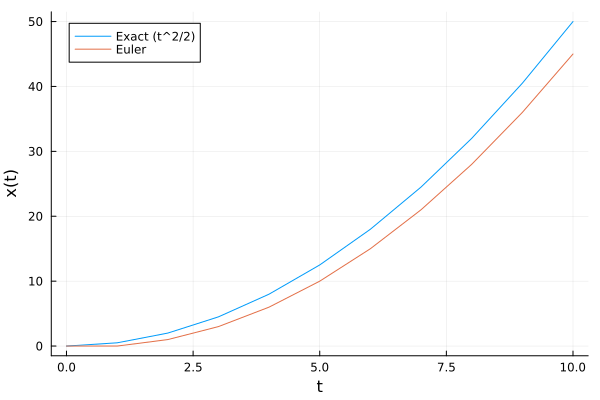

In [19]:
u0 = 0.0
dt = 1.0
T = 10
tspan = 0:dt:T

function reaction(u, p, t)
    return t
end

sol = exact(reaction, u0, tspan, Tsit5(), 1e-10, 1e-10)

numsol, _ = numerical_integration(
    reaction,
    Euler,
    u0,
    dt,
    length(tspan),
    1
)

plot(tspan, sol,
    label="Exact (t^2/2)",
    xlabel="t",
    ylabel="x(t)"
)

plot!(tspan, numsol,
    label="Euler"
)



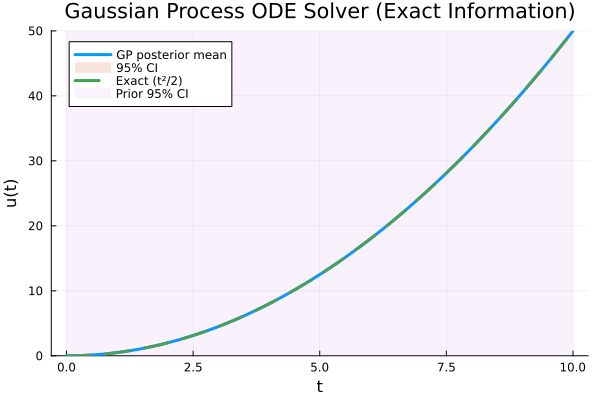

"/Users/shoji/Project_with_Jon/a.png"

In [23]:
using LinearAlgebra
using Plots

ℓ = 10.0
σf = 100.0
prior_mean = 0.0
obs_noise = dt*2
obs_noise = 0.000001

# =====================================================
# Cov(u'(ti),u'(tj))
# =====================================================

function K_LL(ts; ℓ=1.0, σf=1.0)

    n = length(ts)
    K = zeros(n,n)

    for i in 1:n
        for j in 1:n

            Δ = ts[i] - ts[j]

            k = rbf_kernel(
                ts[i],
                ts[j];
                ℓ=ℓ,
                σf=σf
            )

            K[i,j] =
                (1/ℓ^2 - Δ^2/ℓ^4) * k
        end
    end

    K
end

# =====================================================
# Observation covariance
#
# observations =
# [u(0), u'(t1), u'(t2), ...]
# =====================================================

function build_observation_covariance(
    ts;
    ℓ,
    σf
)

    n = length(ts)

    K = zeros(n+1,n+1)

    #
    # Cov(u(0),u(0))
    #

    K[1,1] =
        rbf_kernel(
            0.0,
            0.0;
            ℓ=ℓ,
            σf=σf
        )

    #
    # Cov(u(0),u'(tj))
    #

    for j in 1:n

        tj = ts[j]

        k =
            rbf_kernel(
                0.0,
                tj;
                ℓ=ℓ,
                σf=σf
            )

        K[1,j+1] =
            (-tj)/ℓ^2 * k

        K[j+1,1] =
            K[1,j+1]

    end

    #
    # Cov(u',u')
    #

    K[2:end,2:end] .=
        K_LL(
            ts;
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# Cov(u(t),u'(tj))
# =====================================================

function K_starL(
    X_test,
    ts;
    ℓ=1.0,
    σf=1.0
)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n)

    for i in 1:m
        for j in 1:n

            k =
                rbf_kernel(
                    X_test[i],
                    ts[j];
                    ℓ=ℓ,
                    σf=σf
                )

            K[i,j] =
                (X_test[i]-ts[j]) / ℓ^2 * k
        end
    end

    K
end

# =====================================================
# Cross covariance
# =====================================================

function build_cross_covariance(
    X_test,
    ts;
    ℓ,
    σf
)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n+1)

    #
    # Cov(u(t),u(0))
    #

    for i in 1:m

        K[i,1] =
            rbf_kernel(
                X_test[i],
                0.0;
                ℓ=ℓ,
                σf=σf
            )

    end

    #
    # Cov(u(t),u')
    #

    K[:,2:end] .=
        K_starL(
            X_test,
            ts;
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# ODE
#
# u'(t)=t
#
# exact:
# u(t)=t^2/2
# =====================================================


t_obs =
    collect(0:dt:10)

t_obs = t_obs[2:end]

rhs =
    collect(t_obs)

y =
    vcat(
        [0.0],
        rhs
    )

# =====================================================
# Posterior
# =====================================================

X_test =
    collect(
        range(
            0,
            10,
            length=500
        )
    )

K =
    build_observation_covariance(
        t_obs;
        ℓ=ℓ,
        σf=σf
    )

#
# numerical jitter only
#

#K += 1e-10I

Ks =
    build_cross_covariance(
        X_test,
        t_obs;
        ℓ=ℓ,
        σf=σf
    )

Kss =
    kernel_matrix(
        X_test,
        X_test;
        ℓ=ℓ,
        σf=σf
    )

m_y =
    vcat(
        [prior_mean],
        zeros(length(t_obs))
    )

m_x =
    fill(
        prior_mean,
        length(X_test)
    )

μ =
    m_x +
    Ks * (K \ (y-m_y))

Σ =
    Kss -
    Ks * (K \ Ks')

std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================

u_exact(t) =
    t^2 / 2

# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    ylim=(0,50),
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

std_prior =
    sqrt.(
        diag(
            kernel_matrix(
                X_test,
                X_test;
                ℓ=ℓ,
                σf=σf
            )
        )
    )

μ_prior =
    fill(
        prior_mean,
        length(X_test)
    )

plot!(
    X_test,
    μ_prior .+ 1.96 .* std_prior,
    fillrange=
        μ_prior .- 1.96 .* std_prior,
    fillalpha=0.1,
    linealpha=0,
    label="Prior 95% CI"
)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver (Exact Information)")

display(current())

savefig("a.png")

In [21]:
ℓ_grid = [0.001, 0.1, 0.5, 1.0, 3.0, 5.0, 10.0, 100]

σf_grid = [ 0.001, 0.01,  0.1,  1, 10, 30, 100, 500]

prior_mean = 0.0  # ← スカラーにする

scores = zeros(
    length(ℓ_grid),
    length(σf_grid)
)

# ==========================================
# Grid Search
# ==========================================

for (i, ℓ) in enumerate(ℓ_grid)
    for (j, σf) in enumerate(σf_grid)

        scores[i,j] =
            log_marginal_extended_exact(
                t_obs,
                y;
#                dt=dt,
                ℓ=ℓ,
                σf=σf,
                prior_mean=prior_mean,
                obs_noise = obs_noise
            )

    end
end

for (j, σf) in enumerate(σf_grid)

    println()
    println("========================================")
    println("σf = ", σf)
    println("========================================")

    println(rpad("ℓ", 10), "score")

    for (i, ℓ) in enumerate(ℓ_grid)
        println(rpad(string(ℓ), 10),
                round(scores[i,j], digits=4))
    end
end

best_linear_idx = argmax(scores)

best_i, best_j =
    Tuple(CartesianIndices(scores)[best_linear_idx])

best_ℓ = ℓ_grid[best_i]
best_σf = σf_grid[best_j]

println()
println("Best parameters")
println("----------------")
println("best ℓ    = ", best_ℓ)
println("best σf   = ", best_σf)
println("best score = ", scores[best_i,best_j])




σf = 0.001
ℓ         score
0.001     -195.7004
0.1       -1.9058977927e6
0.5       -9.41309554743e7
1.0       -1.535836492998e8
3.0       -1.626199461662e8
5.0       -1.737869148423e8
10.0      -1.841599195518e8
100.0     -1.923498414773e8

σf = 0.01
ℓ         score
0.001     -30.454
0.1       -19230.553
0.5       -1.9200388357e6
1.0       -1.25632944781e7
3.0       -1.76586120909e7
5.0       -2.24355758601e7
10.0      -4.47417254787e7
100.0     -1.788341658536e8

σf = 0.1
ℓ         score
0.001     -53.8767
0.1       -200.3056
0.5       -19398.1698
1.0       -138760.514
3.0       -261057.0214
5.0       -395436.9402
10.0      -976767.0391
100.0     -5.4622017764e7

σf = 1.0
ℓ         score
0.001     -79.1861
0.1       -35.0592
0.5       -210.0554
1.0       -1397.758
3.0       -3136.7242
5.0       -5587.1624
10.0      -18207.5156
100.0     -1.58111820076e7

σf = 10.0
ℓ         score
0.001     -104.5143
0.1       -58.4819
0.5       -43.2285
1.0       -47.7357
3.0       -38.0655
5.0      

In [22]:
println()
println("================ GRID TABLE ================")

# header
print(rpad("σf \\ ℓ", 10))
for ℓ in ℓ_grid
    print(rpad(string(ℓ), 12))
end
println()

# body
for (j, σf) in enumerate(σf_grid)
    print(rpad(string(σf), 10))
    for (i, ℓ) in enumerate(ℓ_grid)
        print(rpad(round(scores[i,j], digits=4), 12))
    end
    println()
end


================ GRID TABLE ================
σf \ ℓ    0.001       0.1         0.5         1.0         3.0         5.0         10.0        100.0       
0.001     -195.7004   -1.9058977927e6-9.41309554743e7-1.535836492998e8-1.626199461662e8-1.737869148423e8-1.841599195518e8-1.923498414773e8
0.01      -30.454     -19230.553  -1.9200388357e6-1.25632944781e7-1.76586120909e7-2.24355758601e7-4.47417254787e7-1.788341658536e8
0.1       -53.8767    -200.3056   -19398.1698 -138760.514 -261057.0214-395436.9402-976767.0391-5.4622017764e7
1.0       -79.1861    -35.0592    -210.0554   -1397.758   -3136.7242  -5587.1624  -18207.5156 -1.58111820076e7
10.0      -104.5143   -58.4819    -43.2285    -47.7357    -38.0655    -56.4451    -220.2866   -251627.4173
30.0      -116.599    -70.5495    -53.588     -47.4715    -17.9782    -2.9472     -13.7454    -28168.8264 
100.0     -129.8427   -83.7912    -66.6354    -59.3105    -27.4208    -5.9172     11.1365     -2525.1605  
500.0     -147.5466   -101.4949   -